**Implementing Airline Constraints**

In [215]:
using CSV, DataFrames, JuMP, Gurobi, Plots, Random
using LaTeXStrings, StatsPlots, LinearAlgebra

In [216]:
coordinates = CSV.read("data/coordinates_new.csv", DataFrame);
coordinates = coordinates[:, [2,3]];
costs = CSV.read("data/cost_BTS.csv", DataFrame);
capacity = CSV.read("data/capacity.csv", DataFrame);
range = CSV.read("data/range.csv", DataFrame);
ferry_range = CSV.read("data/ferry_range.csv", DataFrame);
no_cargo_range = CSV.read("data/ferry_range.csv", DataFrame);
tradeoff = CSV.read("data/tradeoff.csv", DataFrame);
velocity = CSV.read("data/velocity.csv", DataFrame);

In [217]:
airport_coordinates = Matrix(coordinates);
airport_coordinates = airport_coordinates[1:size(airport_coordinates,1)-1,:];
# aircraft_costs = Matrix(costs);
# aircraft_ranges = Matrix(range);

10×2 Matrix{Float64}:
  -87.909   41.9802
 -122.309   47.4484
 -122.382   37.6192
 -117.19    32.7332
 -104.676   39.8563
  -93.2131  44.8849
  -95.3416  29.9931
  -80.2795  25.7951
  -84.4294  33.6361
  -73.7797  40.6446

In [218]:
# Define distance function
function distance(x_1::Float64, y_1::Float64, x_2::Float64, y_2::Float64)::Float64
    deltax = x_1 - x_2;
    deltay = y_1 - y_2;
    d = sqrt(deltax^2 + deltay^2);
    return d
end

distance (generic function with 1 method)

In [219]:
function distance_matrix(airport_coordinates::Matrix)
    n = size(airport_coordinates,1)
    D = zeros((n,n))
    for i in 1:n
        for j in 1:n
            D[i,j] = distance(airport_coordinates[i,1],airport_coordinates[i,2],airport_coordinates[j,1],airport_coordinates[j,2]) * 60
        end
    end
    return D
end

distance_matrix (generic function with 1 method)

In [220]:
D = distance_matrix(airport_coordinates);

In [221]:
# Initializing possible cities
V = 1:size(airport_coordinates,1);
n = length(V);


**Implementing ASM Objective**

In [251]:
n = 11
m = 5

5

In [253]:
model = Model(Gurobi.Optimizer)

@variable(model, X[i in V, j in V, k in 1:m], Bin);
@variable(model, Y[i in V, k in 1:m], Bin);
@variable(model, 2 <= U[i in V, k in 1:m] <= length(V));

Set parameter Username
Academic license - for non-commercial use only - expires 2024-09-09


In [254]:
fix.(U[1,:], 1; force = true);

In [255]:
@objective(model, Max, sum(capacity[k,"capacity"] * D[i, j] * X[i, j, k] for i in V, j in V, k in 1:m),);

In [257]:
@constraints(model, begin
    # For all nodes and routes, flow out == flow in
    [i in V, k in 1:m], sum(X[i, :, k]) == sum(X[:, i, k])
    # Flow in and out of other nodes is 1
    [i in V; i != 1], sum(X[i, :, :]) == 1
    [i in V; i != 1], sum(X[:, i, :]) == 1
    # MTZ constraints
    [i in V, j in V, k in 1:m; i != 1 && j != 1],
        U[i, k] - U[j, k] + 1 <= (n - 1) * (1 - X[i, j, k])
    # y[i, k] is 1 if node i is in route k
    [i in V, k in 1:m], sum(X[i, :, k]) == Y[i, k]
    # each node can be in at most one route, except node 1, which is in every 
    # route
    [i in V; i != 1], sum(Y[i, :]) <= 1
    # Range constraint
    [i in V, j in V, k in 1:m], D[i,j] * X[i,j,k] <= range[k, "range"]
    end);

In [258]:
optimize!(model)
for k in 1:m
    print("Route $k: 1")
    i = 1
    while true
        for j in V
            if value(X[i, j, k]) > 0.5
                print(" => $j")
                i = j
                break
            end
        end
        if i == 1
            println()
            break
        end
    end
end

Gurobi Optimizer version 10.0.2 build v10.0.2rc0 (mac64[arm])

CPU model: Apple M1
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 1105 rows, 600 columns and 5775 nonzeros
Model fingerprint: 0xd987eb40
Variable types: 50 continuous, 550 integer (550 binary)
Coefficient statistics:
  Matrix range     [1e+00, 3e+03]
  Objective range  [3e+04, 6e+05]
  Bounds range     [1e+00, 1e+01]
  RHS range        [1e+00, 3e+03]
Presolve removed 854 rows and 315 columns
Presolve time: 0.01s
Presolved: 251 rows, 285 columns, 2445 nonzeros
Variable types: 41 continuous, 244 integer (244 binary)

Root relaxation: objective 3.756741e+06, 131 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0 3756740.94    0   12          - 3756740.94      -     -    0s
H    0     0                    2091601.9828 375

In [259]:
Xopt = Array(value.(X[:,:,:]));

[1,4,4]
[2,1,4]
[4,8,4]
[5,9,4]
[6,7,4]
[7,10,4]
[8,6,4]
[9,2,4]
[10,5,4]
[1,3,5]
[3,1,5]


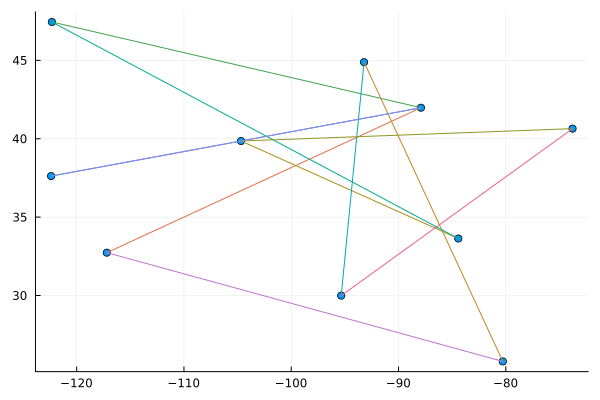

In [261]:
fig = scatter(airport_coordinates[:,1], airport_coordinates[:,2], legend=false);
for k in 1:m
    for i in V
        for j in V
            if (Xopt[i,j,k] > 0.95) 
                print("[" * string(i) * "," * string(j) * "," * string(k) * "]")
                print("\n")
                xcoords = [airport_coordinates[i,1];airport_coordinates[j,1]];
                ycoords = [airport_coordinates[i,2];airport_coordinates[j,2]];
 
                plot!(fig, xcoords, ycoords);
            end
        end
    end
end
fig

**Implementing Block Hour Metric**

In [241]:
n = 11
m = 5

5

In [242]:
model = Model(Gurobi.Optimizer)

@variable(model, X[i in V, j in V, k in 1:m], Bin);
@variable(model, Y[i in V, k in 1:m], Bin);
@variable(model, 2 <= U[i in V, k in 1:m] <= length(V));

Set parameter Username
Academic license - for non-commercial use only - expires 2024-09-09


In [243]:
fix.(U[1,:], 1; force = true);

In [244]:
@objective(model, Max, sum((D[i, j]/velocity[k,"velocity"]) * X[i, j, k] for i in V, j in V, k in 1:m),);

In [262]:
@constraints(model, begin
    # For all nodes and routes, flow out == flow in
    [i in V, k in 1:m], sum(X[i, :, k]) == sum(X[:, i, k])
    # Flow in and out of other nodes is 1
    [i in V; i != 1], sum(X[i, :, :]) == 1
    [i in V; i != 1], sum(X[:, i, :]) == 1
    # MTZ constraints
    [i in V, j in V, k in 1:m; i != 1 && j != 1],
        U[i, k] - U[j, k] + 1 <= (n - 1) * (1 - X[i, j, k])
    # y[i, k] is 1 if node i is in route k
    [i in V, k in 1:m], sum(X[i, :, k]) == Y[i, k]
    # each node can be in at most one route, except node 1, which is in every 
    # route
    [i in V; i != 1], sum(Y[i, :]) <= 1
    # Range constraint
    [i in V, j in V, k in 1:m], D[i,j] * X[i,j,k] <= range[k, "range"]
    end);

In [263]:
optimize!(model)
for k in 1:m
    print("Route $k: 1")
    i = 1
    while true
        for j in V
            if value(X[i, j, k]) > 0.5
                print(" => $j")
                i = j
                break
            end
        end
        if i == 1
            println()
            break
        end
    end
end

Gurobi Optimizer version 10.0.2 build v10.0.2rc0 (mac64[arm])

CPU model: Apple M1
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 2137 rows, 600 columns and 9745 nonzeros
Model fingerprint: 0x4a519399
Variable types: 50 continuous, 550 integer (550 binary)
Coefficient statistics:
  Matrix range     [1e+00, 3e+03]
  Objective range  [3e+04, 6e+05]
  Bounds range     [1e+00, 1e+01]
  RHS range        [1e+00, 3e+03]

MIP start from previous solve produced solution with objective 3.67232e+06 (0.00s)
Loaded MIP start from previous solve with objective 3.67232e+06

Presolve removed 1886 rows and 315 columns
Presolve time: 0.01s
Presolved: 251 rows, 285 columns, 2445 nonzeros
Variable types: 41 continuous, 244 integer (244 binary)

Root relaxation: objective 3.756741e+06, 122 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    Be

In [264]:
Xopt = Array(value.(X[:,:,:]));

[1,1,1]
[1,1,3]
[1,4,4]
[2,1,4]
[4,8,4]
[5,9,4]
[6,7,4]
[7,10,4]
[8,6,4]
[9,2,4]
[10,5,4]
[1,3,5]
[3,1,5]


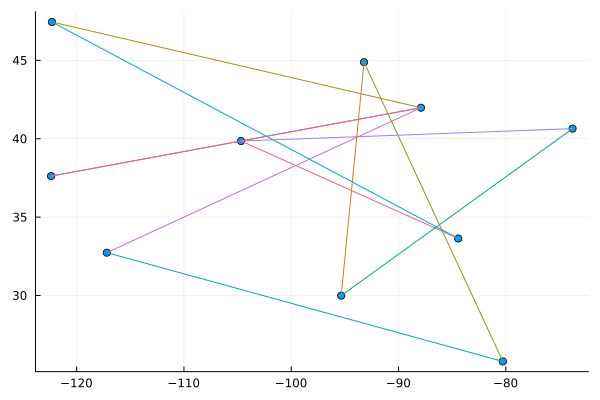

In [265]:
fig = scatter(airport_coordinates[:,1], airport_coordinates[:,2], legend=false);
for k in 1:m
    for i in V
        for j in V
            if (Xopt[i,j,k] > 0.95) 
                print("[" * string(i) * "," * string(j) * "," * string(k) * "]")
                print("\n")
                xcoords = [airport_coordinates[i,1];airport_coordinates[j,1]];
                ycoords = [airport_coordinates[i,2];airport_coordinates[j,2]];
 
                plot!(fig, xcoords, ycoords);
            end
        end
    end
end
fig

**Implementing Payload and Range Constraints**

In [267]:
n = 11
m = 5

5

In [268]:
model = Model(Gurobi.Optimizer)

@variable(model, X[i in V, j in V, k in 1:m], Bin);
@variable(model, Y[i in V, k in 1:m], Bin);
@variable(model, 2 <= U[i in V, k in 1:m] <= length(V));
@variable(model, Z[i in V, j in V] >= 0);

Set parameter Username
Academic license - for non-commercial use only - expires 2024-09-09


In [269]:
fix.(U[1,:], 1; force = true);

In [270]:
@objective(model, Max, sum((X[i, j, k] * (Z[i,j] * D[i,j] * (2.7205 * (0.868976 * D[i,j])^(-0.112) - 1) - costs[k, "cost"] * (D[i,j]/velocity[k,"velocity"]))) for i in V, j in V, k in 1:m),);

ErrorException: Expression contains an invalid NaN constant. This could be produced by `Inf - Inf`.

In [271]:
@constraints(model, begin
    # For all nodes and routes, flow out == flow in
    [i in V, k in 1:m], sum(X[i, :, k]) == sum(X[:, i, k])
    # Flow in and out of other nodes is 1
    [i in V; i != 1], sum(X[i, :, :]) == 1
    [i in V; i != 1], sum(X[:, i, :]) == 1
    # MTZ constraints
    [i in V, j in V, k in 1:m; i != 1 && j != 1],
        U[i, k] - U[j, k] + 1 <= (n - 1) * (1 - X[i, j, k])
    # y[i, k] is 1 if node i is in route k
    [i in V, k in 1:m], sum(X[i, :, k]) == Y[i, k]
    # each node can be in at most one route, except node 1, which is in every 
    # route
    [i in V; i != 1], sum(Y[i, :]) <= 1
    # Range constraint
    [i in V, j in V, k in 1:m], D[i,j] * X[i,j,k] <= ferry_range[k, "ferry_range"] - tradeoff[k,"tradeoff"](220 * Z[i,j])
    # Capacity constraint
    [i in V, j in V, k in 1:m], Z[i,j] * X[i,j,k] <= capacity[k, "capacity"]
    end);

MethodError: MethodError: objects of type Float64 are not callable
Maybe you forgot to use an operator such as *, ^, %, / etc. ?

In [ ]:
optimize!(model)
for k in 1:m
    print("Route $k: 1")
    i = 1
    while true
        for j in V
            if value(X[i, j, k]) > 0.5
                print(" => $j")
                i = j
                break
            end
        end
        if i == 1
            println()
            break
        end
    end
end

In [ ]:
Xopt = Array(value.(X[:,:,:]));

In [ ]:
fig = scatter(airport_coordinates[:,1], airport_coordinates[:,2], legend=false);
for k in 1:n
    for i in V
        for j in V
            if (Xopt[i,j,k] > 0.95) 
                print("[" * string(i) * "," * string(j) * "," * string(k) * "]")
                print("\n")
                xcoords = [airport_coordinates[i,1];airport_coordinates[j,1]];
                ycoords = [airport_coordinates[i,2];airport_coordinates[j,2]];
 
                plot!(fig, xcoords, ycoords);
            end
        end
    end
end
fig